# Datasets gyroscope analysis

This notebooks objective is to analyze the gyroscope timeseries of two datasets. PAMAP2 and Opportunity.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Functions

In [2]:
def plot_time_series(data, title, min_y_limit=None, max_y_limit=None):
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="darkgrid")  # Set seaborn style
    plt.plot(data)
    plt.title(title)
    plt.xlabel('Time')
    plt.ylabel('Value')
    if(min_y_limit is not None and max_y_limit is not None):
        plt.ylim(min_y_limit, max_y_limit)  # Set y-axis limits
    plt.grid(True)
    plt.show()

In [3]:
def plot_two_time_series(data1, label1, data2, label2, title, min_y_limit=None, max_y_limit=None):
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="darkgrid")  # Set seaborn style
    plt.plot(data1, label=label1)
    plt.plot(data2, label=label2)
    plt.title(title)
    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    if(min_y_limit is not None and max_y_limit is not None):
        plt.ylim(min_y_limit, max_y_limit)  # Set y-axis limits
    plt.grid(True)
    plt.show()

In [4]:
def calculate_recurrence_plot(time_series, threshold=0.1):
    """
    Calculate the recurrence matrix for a given time series.
    
    Parameters:
    - time_series: np.array or list, the input time series data.
    - threshold: float, the distance threshold for determining recurrence.
    
    Returns:
    - rec_matrix: np.array, the recurrence matrix.
    """
    time_series = np.asarray(time_series)
    n = len(time_series)
    rec_matrix = np.zeros((n, n))
    
    for i in range(n):
        for j in range(n):
            distance = np.abs(time_series[i] - time_series[j])
            rec_matrix[i, j] = 1 if distance <= threshold else 0
    
    return rec_matrix

In [5]:
def plot_recurrence_matrix(rec_matrix, title, ax):
    """
    Plot the recurrence matrix using Seaborn and Matplotlib.
    
    Parameters:
    - rec_matrix: np.array, the recurrence matrix to be plotted.
    - title: str, title for the plot.
    - ax: matplotlib.axes.Axes, the axes to plot on.
    """
    sns.heatmap(rec_matrix, cmap="binary", square=True, ax=ax, cbar=False)
    
    # Set ticks to show numbers by 20s
    matrix_len = rec_matrix.shape[0]
    tick_labels = np.arange(0, matrix_len, 20)
    
    ax.set_xticks(tick_labels + 0.5)  # Adjust ticks to be centered
    ax.set_yticks(tick_labels + 0.5)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_yticklabels(tick_labels, rotation=0)

    ax.set_title(title)
    ax.set_xlabel("Time Index")
    ax.set_ylabel("Time Index")

In [6]:
def plot_two_recurrence_matrices(time_series1, time_series2, title1, title2, threshold=0.1):
    """
    Plot two recurrence matrices side-by-side for two time series.
    
    Parameters:
    - time_series1: np.array or list, the first time series data.
    - time_series2: np.array or list, the second time series data.
    - threshold: float, the distance threshold for determining recurrence.
    """
    # Calculate recurrence matrices
    rec_matrix1 = calculate_recurrence_plot(time_series1, threshold)
    rec_matrix2 = calculate_recurrence_plot(time_series2, threshold)
    
    # Create subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
    
    # Plot recurrence matrices
    plot_recurrence_matrix(rec_matrix1, title1, ax1)
    plot_recurrence_matrix(rec_matrix2, title2, ax2)
    
    plt.tight_layout()
    plt.show()

In [7]:
def recurrence_plot_vector(data, eps):
    N = len(data)
    recurrence_matrix = np.zeros((N, N))

    # Calculate the Euclidean distance between vectors
    for i in range(N):
        for j in range(N):
            distance = np.linalg.norm(data[i] - data[j])
            recurrence_matrix[i, j] = distance

    # Apply the threshold
    recurrence_matrix = (recurrence_matrix <= eps).astype(int)
    
    return recurrence_matrix

In [8]:
def plot_recurrence_matrix_vector(R, title, tick_jump = 20):
    plt.figure(figsize=(8, 8))
    
    sns.heatmap(R, cmap="binary", square=True, cbar=False)

    # Set ticks to show numbers by 5s
    tick_labels = np.arange(0, R.shape[0], tick_jump)
    plt.xticks(ticks=tick_labels + 0.5, labels=tick_labels, rotation=0)
    plt.yticks(ticks=tick_labels + 0.5, labels=tick_labels, rotation=0)

    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Time")
    plt.show()

In [9]:
def plot_recurrence_by_activity(data, threshold, step):
    num_keys = len(data)
    num_plots_per_key = 4
    fig, axes = plt.subplots(num_keys, num_plots_per_key, figsize=(20, 20))

    for i, (key, value) in enumerate(data.items()):
        start = 100
        for j in range(num_plots_per_key):
            activity_data = value[start:start+step]
            R = recurrence_plot_vector(activity_data, threshold)
            ax = axes[i, j]
            cax = ax.matshow(R, cmap='binary')
            ax.set_title(f'{key} - Plot {j+1}')
            ax.set_xticks([])
            ax.set_yticks([])
            start += step

    plt.tight_layout()
    plt.show()

## PAMAP2 Dataset

In [11]:
# Function to normalize columns
def normalize_group(group):
    group[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']] = (group[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']] - group[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']].mean()) / group[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']].std()
    return group

pamap2 = pd.read_csv('pamap_balanced.csv')
pamap2 = pamap2.groupby('subject_id').apply(normalize_group)
pamap2 = pamap2.reset_index(drop=True)
pamap2

C:\Users\tulio\AppData\Local\Temp\ipykernel_15312\276392561.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pamap2 = pamap2.groupby('subject_id').apply(normalize_group)


,timestamp,activity_id,hand_acc_16g_x,hand_acc_16g_y,hand_acc_16g_z,hand_acc_6g_x,hand_acc_6g_y,hand_acc_6g_z,hand_gyro_x,hand_gyro_y,hand_gyro_z,hand_mag_x,hand_mag_y,hand_mag_z,subject_id
0,309.53,2,2.124620,9.24108,2.77335,2.424750,9.12390,3.02166,-0.025334,-0.060346,-0.007292,15.0033,-67.00450,-1.055520,1
1,309.54,2,2.338250,9.27392,2.39156,2.394240,9.13917,2.96125,-0.023470,-0.073357,0.003876,14.5708,-66.98840,-0.356026,1
2,309.55,2,2.227290,9.23752,2.46700,2.378790,9.21468,2.84029,-0.043238,-0.100840,-0.003243,14.6740,-67.31640,-0.707928,1
3,309.56,2,2.190040,9.12433,2.50531,2.377660,9.13912,2.78006,-0.100765,-0.077383,0.002216,14.7736,-67.42350,-1.288870,1
4,309.57,2,2.391820,9.23971,2.85433,2.361820,9.04862,2.78027,-0.099337,-0.084452,0.005050,15.1053,-66.56780,-1.630630,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926023,3630.07,5,0.489770,2.82383,9.23639,0.374732,2.89221,9.30422,0.078310,-0.080624,0.035942,17.7034,-4.55562,-41.179600,8
926024,3630.08,5,0.370253,2.70955,9.08103,0.526067,2.89119,9.37958,0.068326,-0.124859,0.037895,17.9510,-4.56875,-41.048800,8
926025,3630.09,5,0.644139,2.70986,9.35454,0.630675,2.81489,9.34943,0.086694,-0.087619,0.051403,17.9572,-4.94146,-41.177700,8
926026,3630.10,5,0.566153,2.74771,9.27627,0.720712,2.70858,9.40998,0.074588,-0.047181,0.056104,17.7079,-4.80414,-41.309300,8


In [14]:
walking_data = pamap2[(pamap2['activity_id'] == 4) & (pamap2['subject_id'] == 5)]
walking_vectors = walking_data[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']].to_numpy()

standing_data = pamap2[(pamap2['activity_id'] == 3) & (pamap2['subject_id'] == 5)]
standing_vectors = standing_data[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']].to_numpy()

sitting_data = pamap2[(pamap2['activity_id'] == 2) & (pamap2['subject_id'] == 5)]
sitting_vectors = sitting_data[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']].to_numpy()

jogging_data = pamap2[(pamap2['activity_id'] == 5) & (pamap2['subject_id'] == 5)]
jogging_vectors = jogging_data[['hand_gyro_x', 'hand_gyro_y', 'hand_gyro_z']].to_numpy()

start = 100
end = start + 200
threshold_axis = 0.025
threshold_vector = 0.04

print(len(walking_data)), print(len(standing_data)), print(len(sitting_data)), print(len(jogging_data))

30909
22125
26826
24586


(None, None, None, None)

### Time-series plot

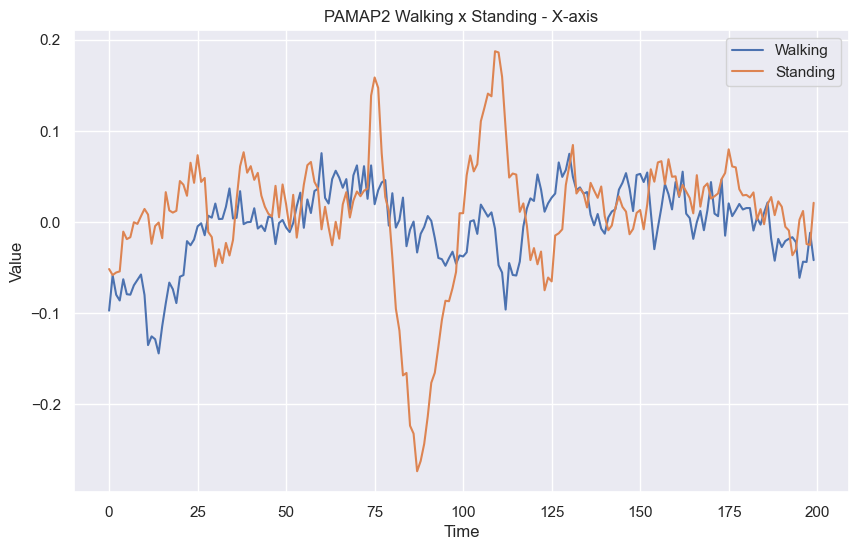

In [15]:
plot_two_time_series(walking_data['hand_gyro_x'].iloc[start:end].reset_index(drop=True), "Walking", standing_data['hand_gyro_x'].iloc[start:end].reset_index(drop=True), "Standing", 'PAMAP2 Walking x Standing - X-axis')

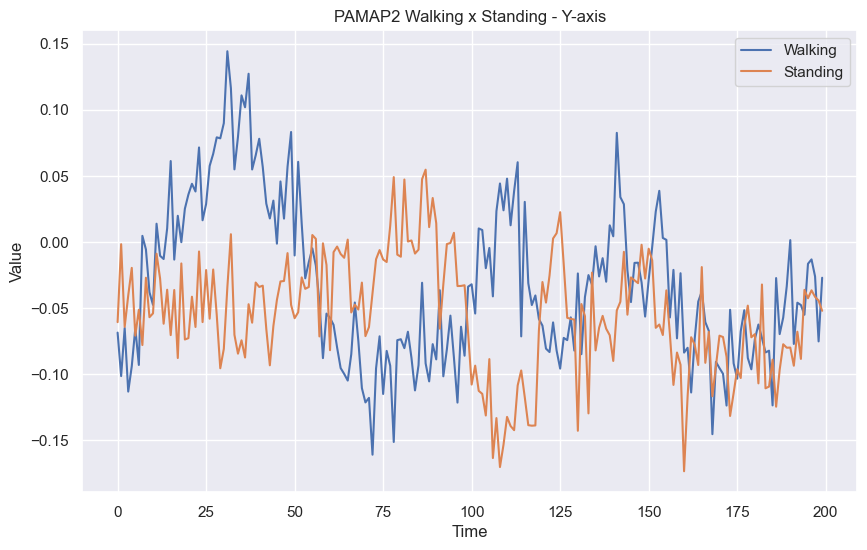

In [16]:
plot_two_time_series(walking_data['hand_gyro_y'].iloc[start:end].reset_index(drop=True), "Walking", standing_data['hand_gyro_y'].iloc[start:end].reset_index(drop=True), "Standing", 'PAMAP2 Walking x Standing - Y-axis')

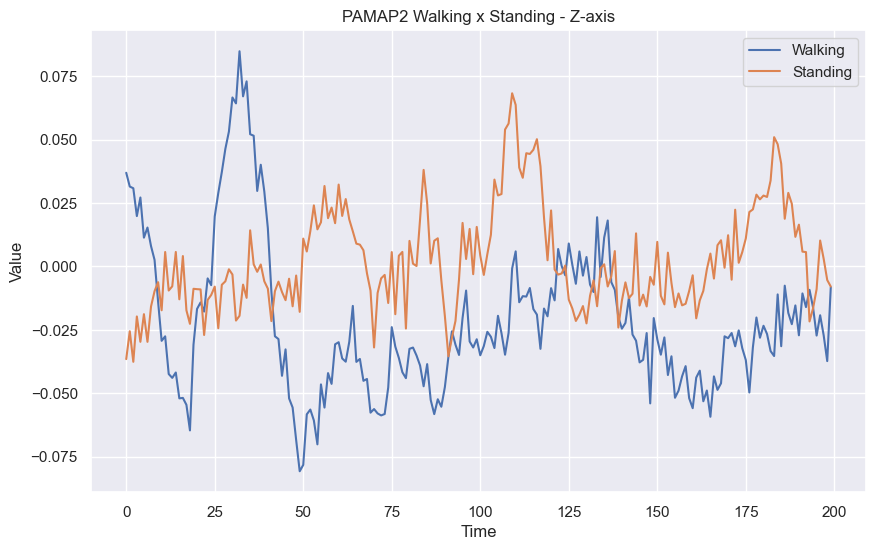

In [17]:
plot_two_time_series(walking_data['hand_gyro_z'].iloc[start:end].reset_index(drop=True), "Walking", standing_data['hand_gyro_z'].iloc[start:end].reset_index(drop=True), "Standing", 'PAMAP2 Walking x Standing - Z-axis')

### Recurrence plot

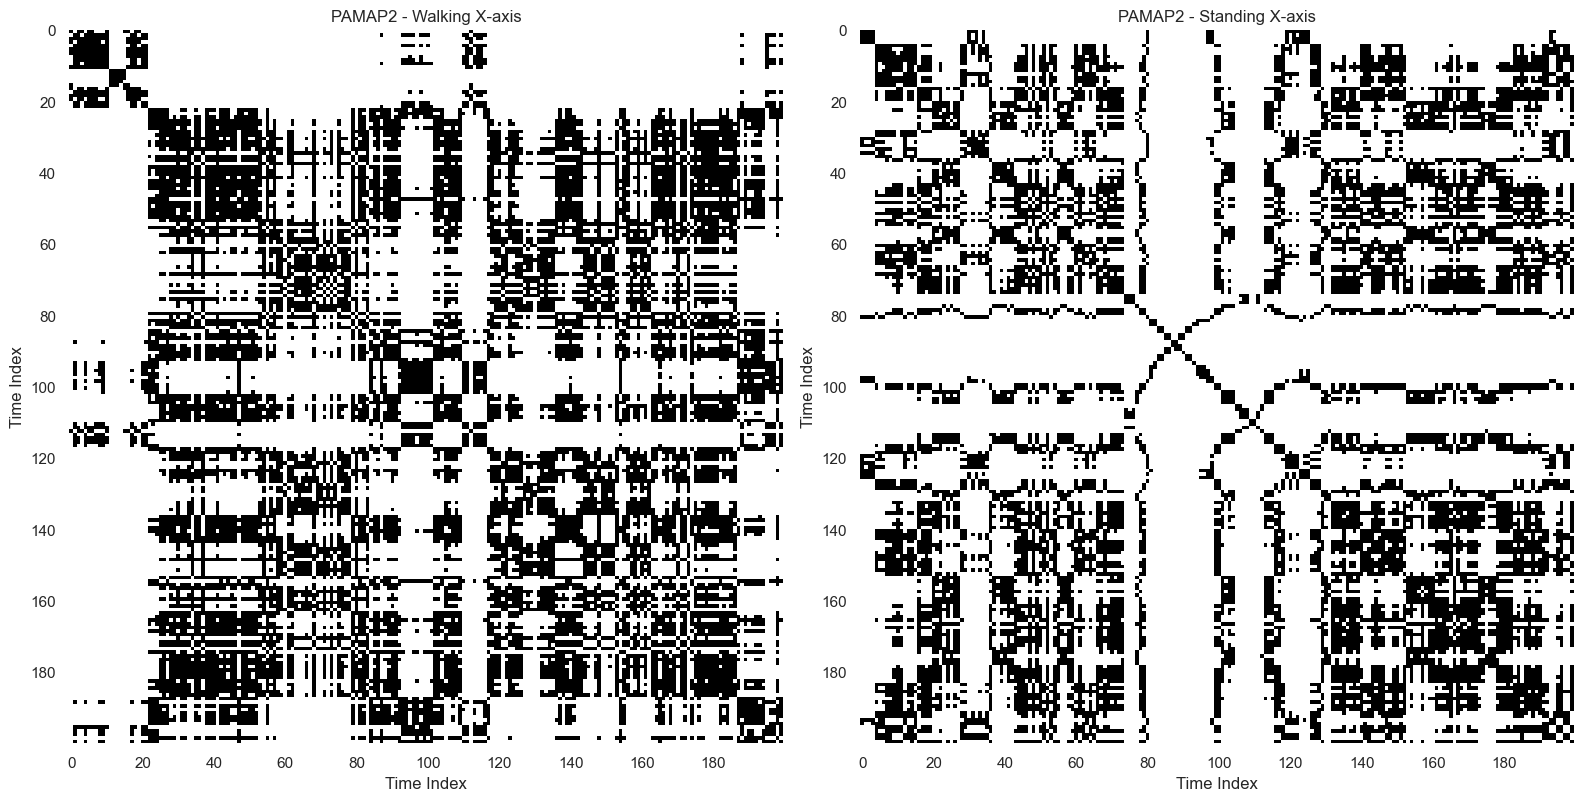

In [18]:
rec_matrix = plot_two_recurrence_matrices(walking_data['hand_gyro_x'].iloc[start:end].values, 
                                          standing_data['hand_gyro_x'].iloc[start:end].values, 
                                          "PAMAP2 - Walking X-axis", 
                                          "PAMAP2 - Standing X-axis", 
                                          threshold_axis)

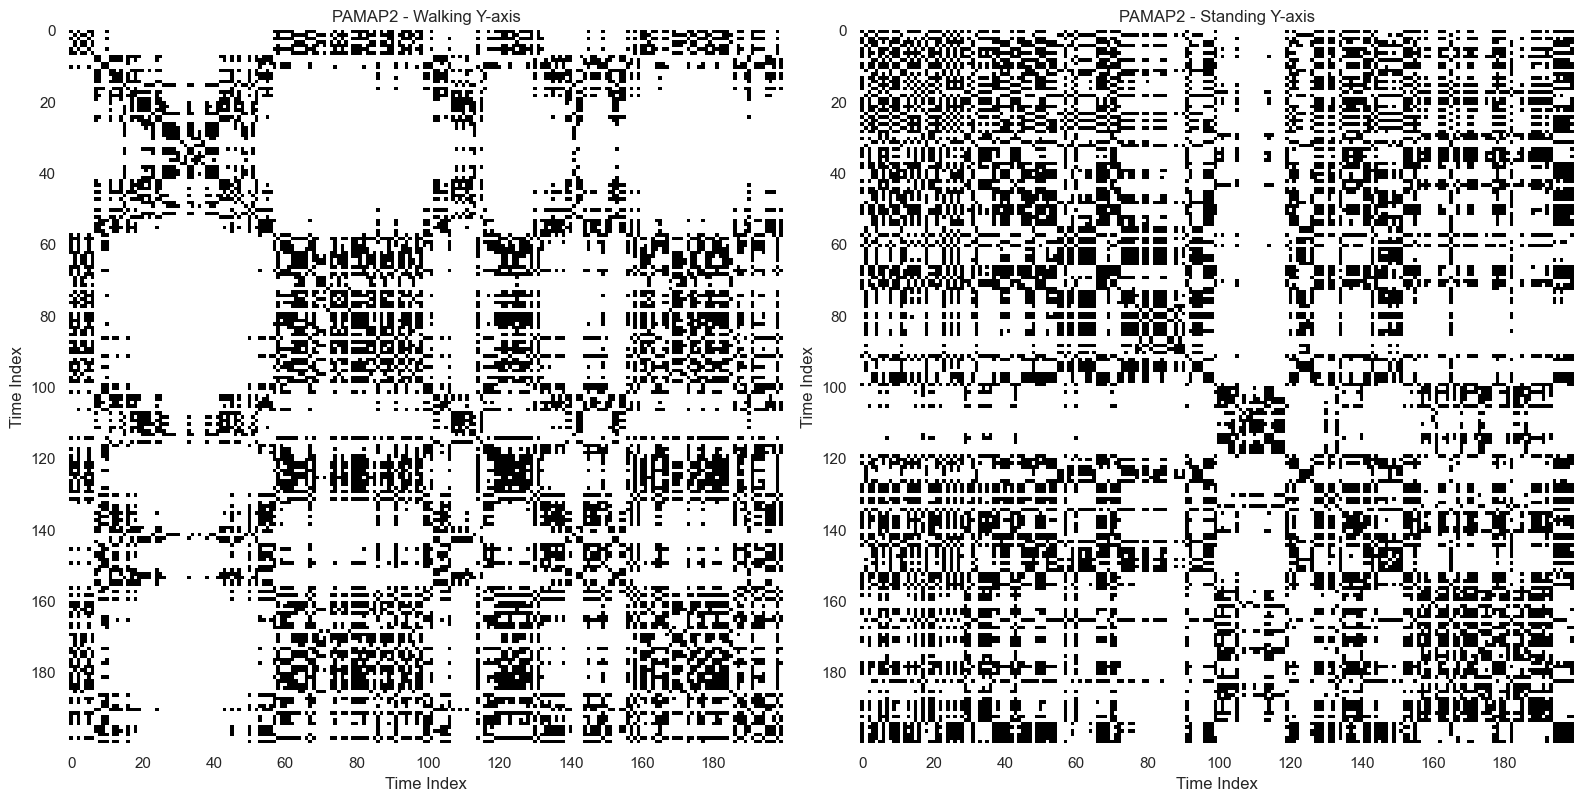

In [19]:
rec_matrix = plot_two_recurrence_matrices(walking_data['hand_gyro_y'].iloc[start:end].values, 
                                          standing_data['hand_gyro_y'].iloc[start:end].values, 
                                          "PAMAP2 - Walking Y-axis", 
                                          "PAMAP2 - Standing Y-axis", 
                                          threshold_axis)

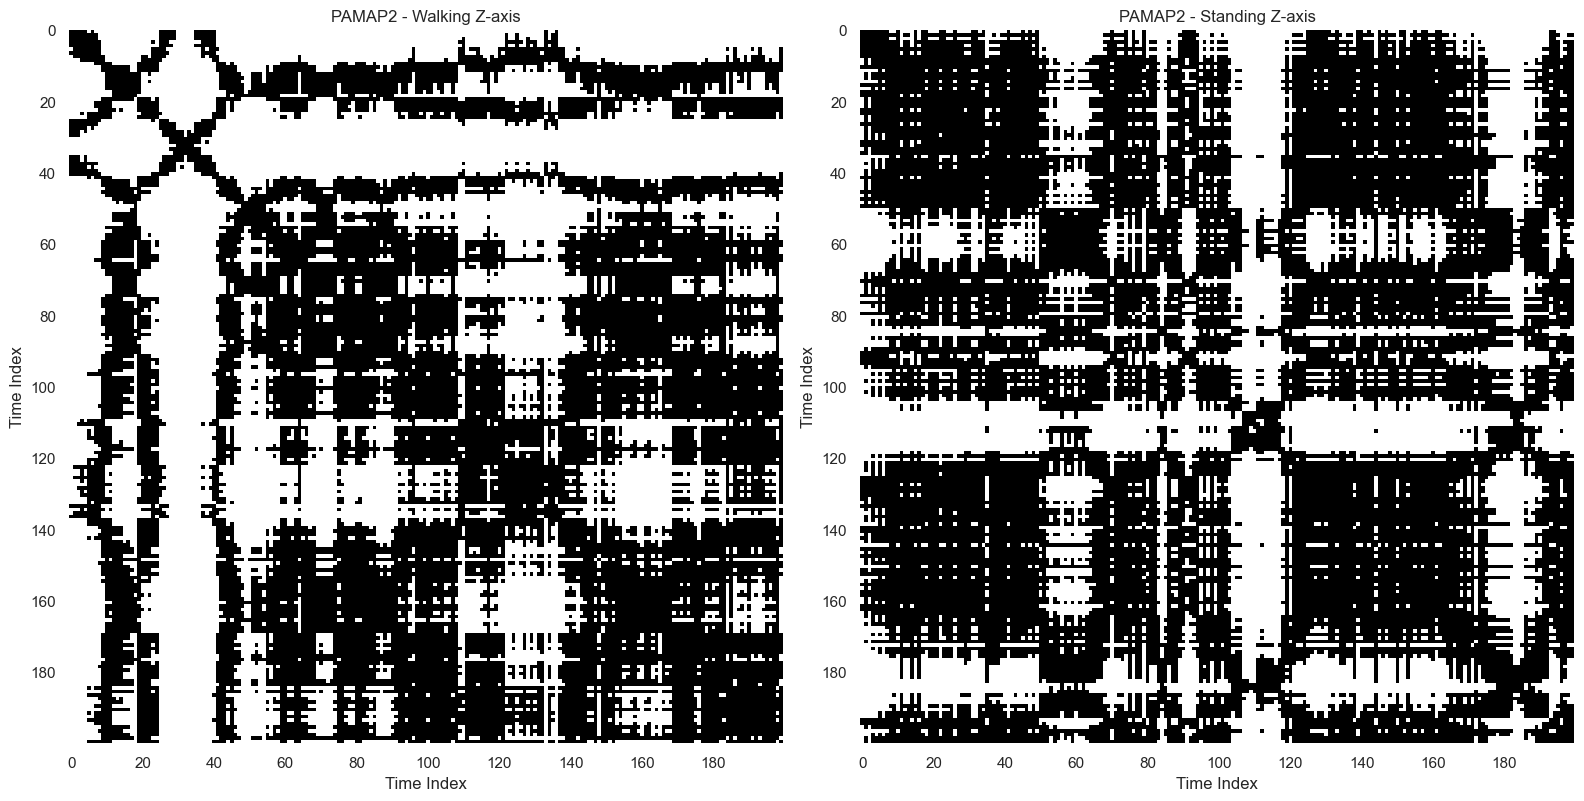

In [20]:
rec_matrix = plot_two_recurrence_matrices(walking_data['hand_gyro_z'].iloc[start:end].values, 
                                          standing_data['hand_gyro_z'].iloc[start:end].values, 
                                          "PAMAP2 - Walking Z-axis", 
                                          "PAMAP2 - Standing Z-axis", 
                                          threshold_axis)

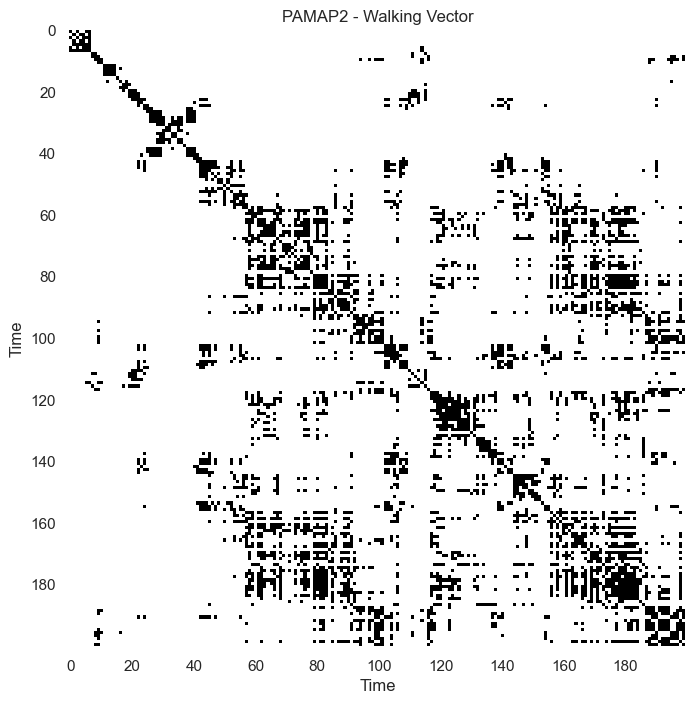

In [21]:
R = recurrence_plot_vector(walking_vectors[start:end,:], threshold_vector)
plot_recurrence_matrix_vector(R, 'PAMAP2 - Walking Vector')

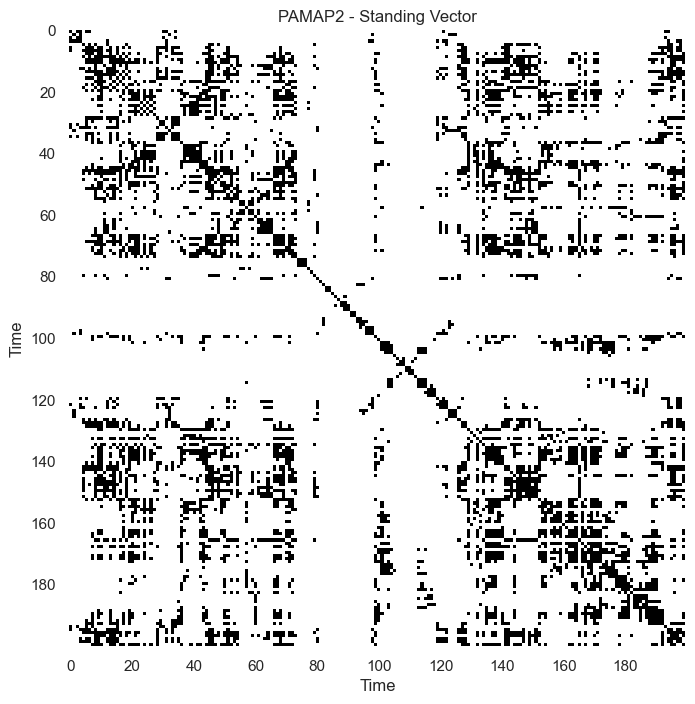

In [22]:
R = recurrence_plot_vector(standing_vectors[start:end,:], threshold_vector)
plot_recurrence_matrix_vector(R, 'PAMAP2 - Standing Vector')

### Multiple recurrence plots

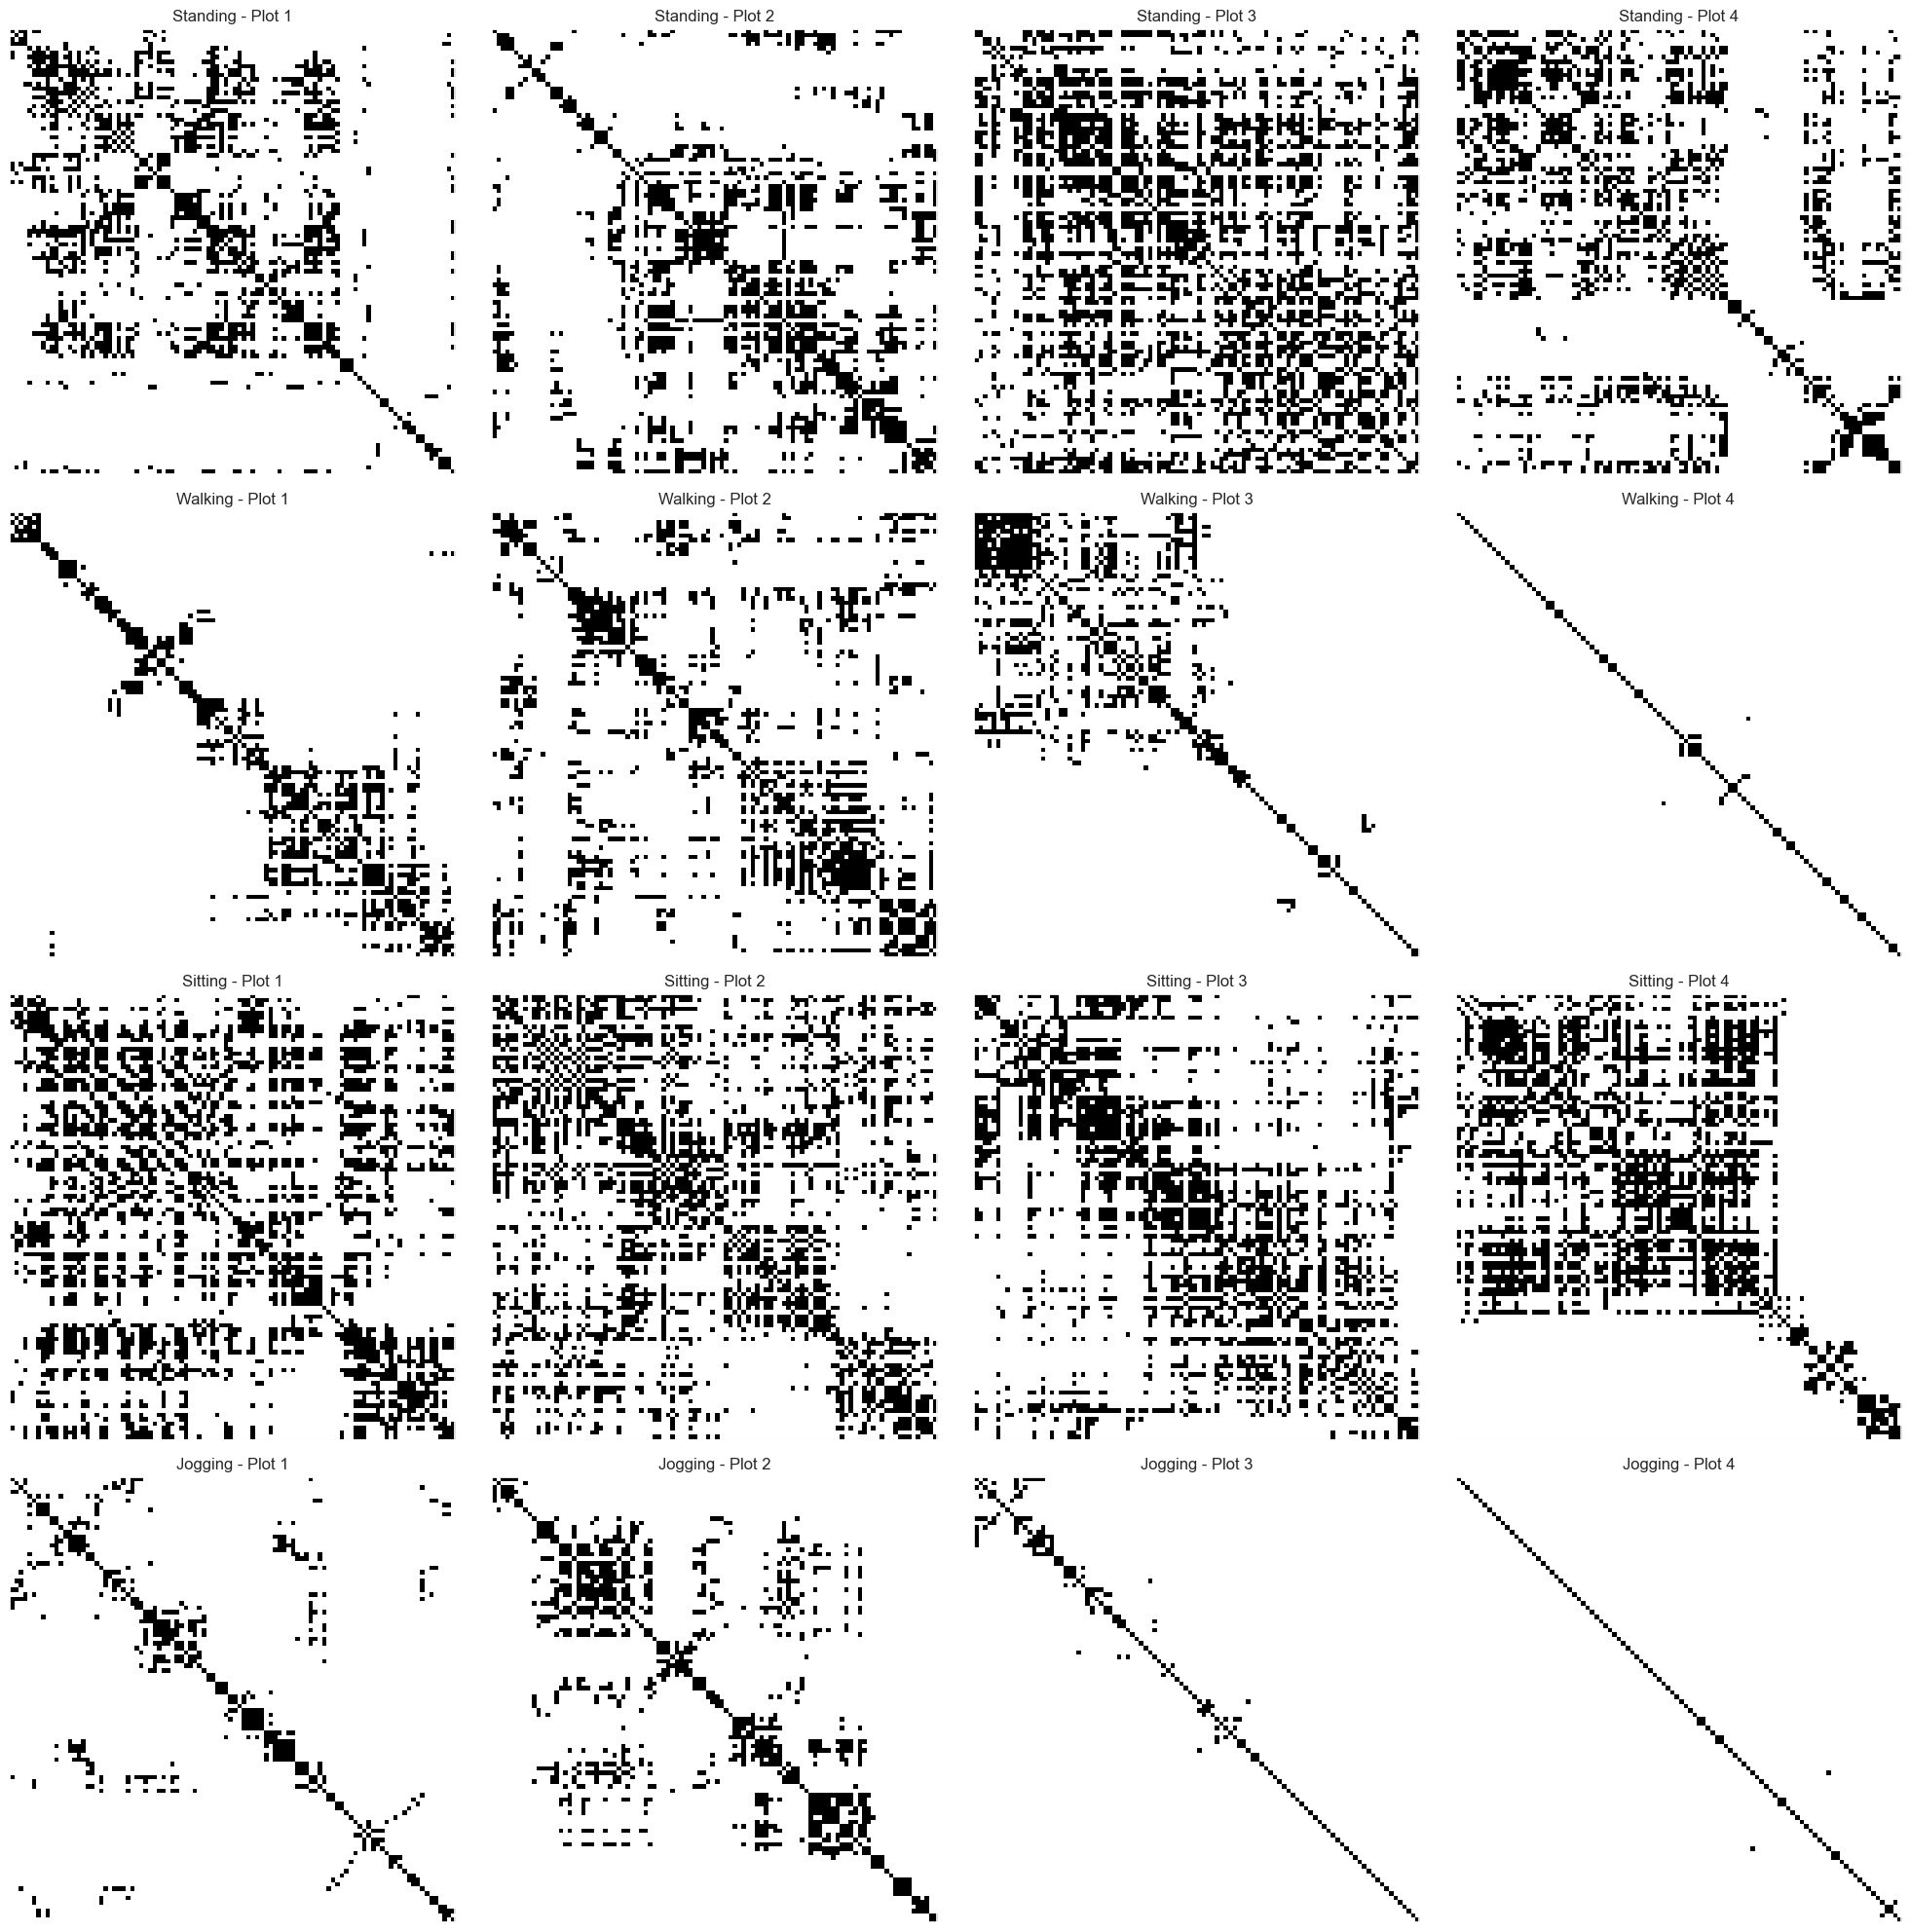

In [23]:
data = {"Standing": standing_vectors, "Walking": walking_vectors, "Sitting": sitting_vectors, "Jogging": jogging_vectors}

plot_recurrence_by_activity(data, 0.04, step=100)

## Opportunity 

In [24]:
# Function to normalize columns
def normalize_group(group):
    group[['gyroX', 'gyroY', 'gyroZ']] = (group[['gyroX', 'gyroY', 'gyroZ']] - group[['gyroX', 'gyroY', 'gyroZ']].mean()) / group[['gyroX', 'gyroY', 'gyroZ']].std()
    return group

opportunity = pd.read_csv('opportunity_preprocessed.csv')
opportunity = opportunity.dropna()
opportunity = opportunity.groupby('user_id').apply(normalize_group)
opportunity = opportunity.reset_index(drop=True)
opportunity

C:\Users\tulio\AppData\Local\Temp\ipykernel_15312\2213672487.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  opportunity = opportunity.groupby('user_id').apply(normalize_group)


,timestamp,accX,accY,accZ,gyroX,gyroY,gyroZ,magneticX,magneticY,magneticZ,activity,user_id
0,0,-920.0,-358.0,171.0,-0.081052,0.061540,0.009110,389.0,202.0,593.0,0,1
1,33,-942.0,-357.0,161.0,-0.286446,-0.019531,-0.024229,390.0,196.0,597.0,0,1
2,67,-928.0,-357.0,143.0,-0.414670,0.009532,0.010443,392.0,192.0,598.0,0,1
3,100,-897.0,-377.0,142.0,-0.322064,0.060010,0.017111,390.0,187.0,601.0,0,1
4,133,-877.0,-398.0,153.0,-0.299506,0.105899,0.078454,389.0,179.0,605.0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
854319,1008123,-998.0,-422.0,-52.0,0.333149,1.133520,-0.121603,145.0,721.0,-92.0,0,5
854320,1008157,-980.0,-361.0,14.0,0.599786,0.936848,-0.171322,142.0,720.0,-101.0,0,5
854321,1008190,-925.0,-360.0,44.0,0.566048,0.514270,-0.258043,139.0,721.0,-111.0,0,5
854322,1008223,-939.0,-333.0,20.0,0.249349,0.191356,-0.184042,136.0,720.0,-120.0,0,5


In [25]:
opportunity['activity'].value_counts()

activity
1    343119
2    197222
0    152420
4    136557
5     25006
Name: count, dtype: int64

In [26]:
walking_data = opportunity[(opportunity['activity'] == 2) & (opportunity['user_id'] == 1)]
walking_vectors = walking_data[['gyroX', 'gyroY', 'gyroZ']].to_numpy()

standing_data = opportunity[(opportunity['activity'] == 1) & (opportunity['user_id'] == 1)]
standing_vectors = standing_data[['gyroX', 'gyroY', 'gyroZ']].to_numpy()

sitting_data = opportunity[(opportunity['activity'] == 4) & (opportunity['user_id'] == 1)]
sitting_vectors = sitting_data[['gyroX', 'gyroY', 'gyroZ']].to_numpy()

end = start + 60

threshold_axis = 0.1
threshold_vector = 0.2

print(len(walking_data)), print(len(standing_data))

53695
87257


(None, None)

### Time-series plot

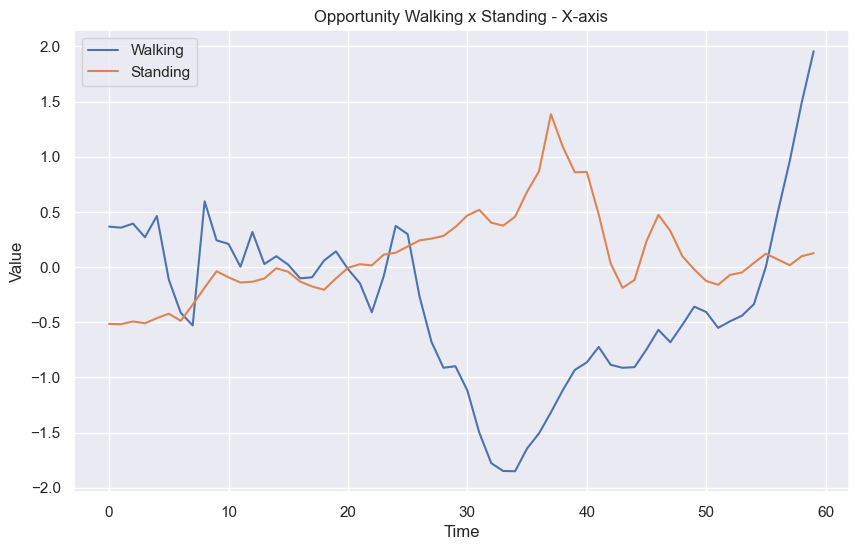

In [27]:
plot_two_time_series(walking_data['gyroX'].iloc[start:end].reset_index(drop=True), "Walking", standing_data['gyroX'].iloc[start:end].reset_index(drop=True), "Standing", 'Opportunity Walking x Standing - X-axis')

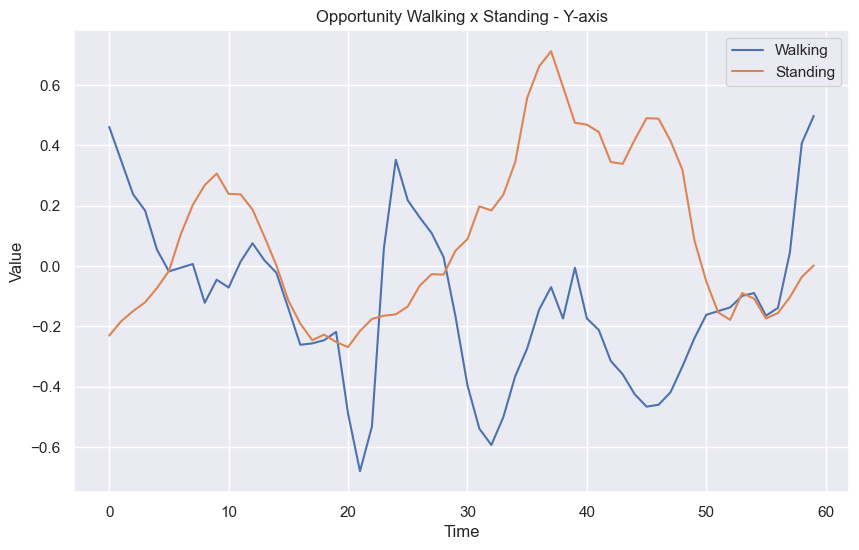

In [28]:
plot_two_time_series(walking_data['gyroY'].iloc[start:end].reset_index(drop=True), "Walking", standing_data['gyroY'].iloc[start:end].reset_index(drop=True), "Standing", 'Opportunity Walking x Standing - Y-axis')

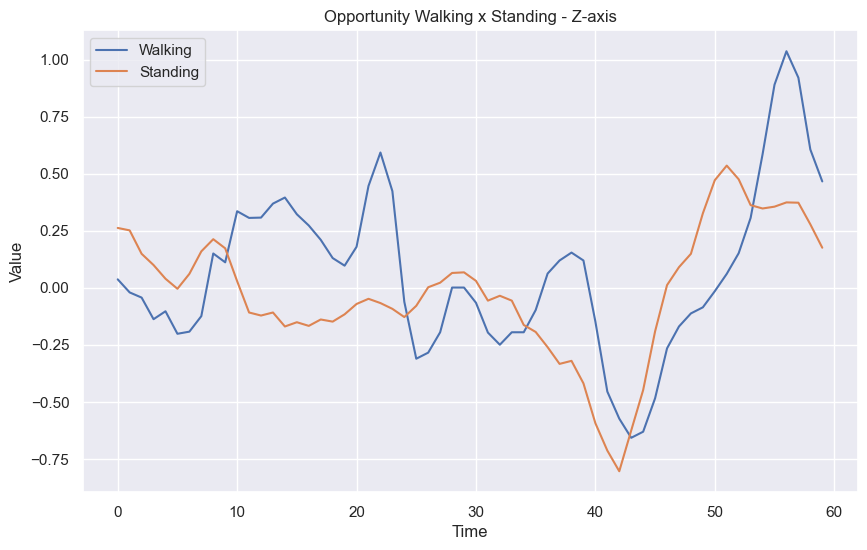

In [29]:
plot_two_time_series(walking_data['gyroZ'].iloc[start:end].reset_index(drop=True), "Walking", standing_data['gyroZ'].iloc[start:end].reset_index(drop=True), "Standing", 'Opportunity Walking x Standing - Z-axis')

### Recurrence plot

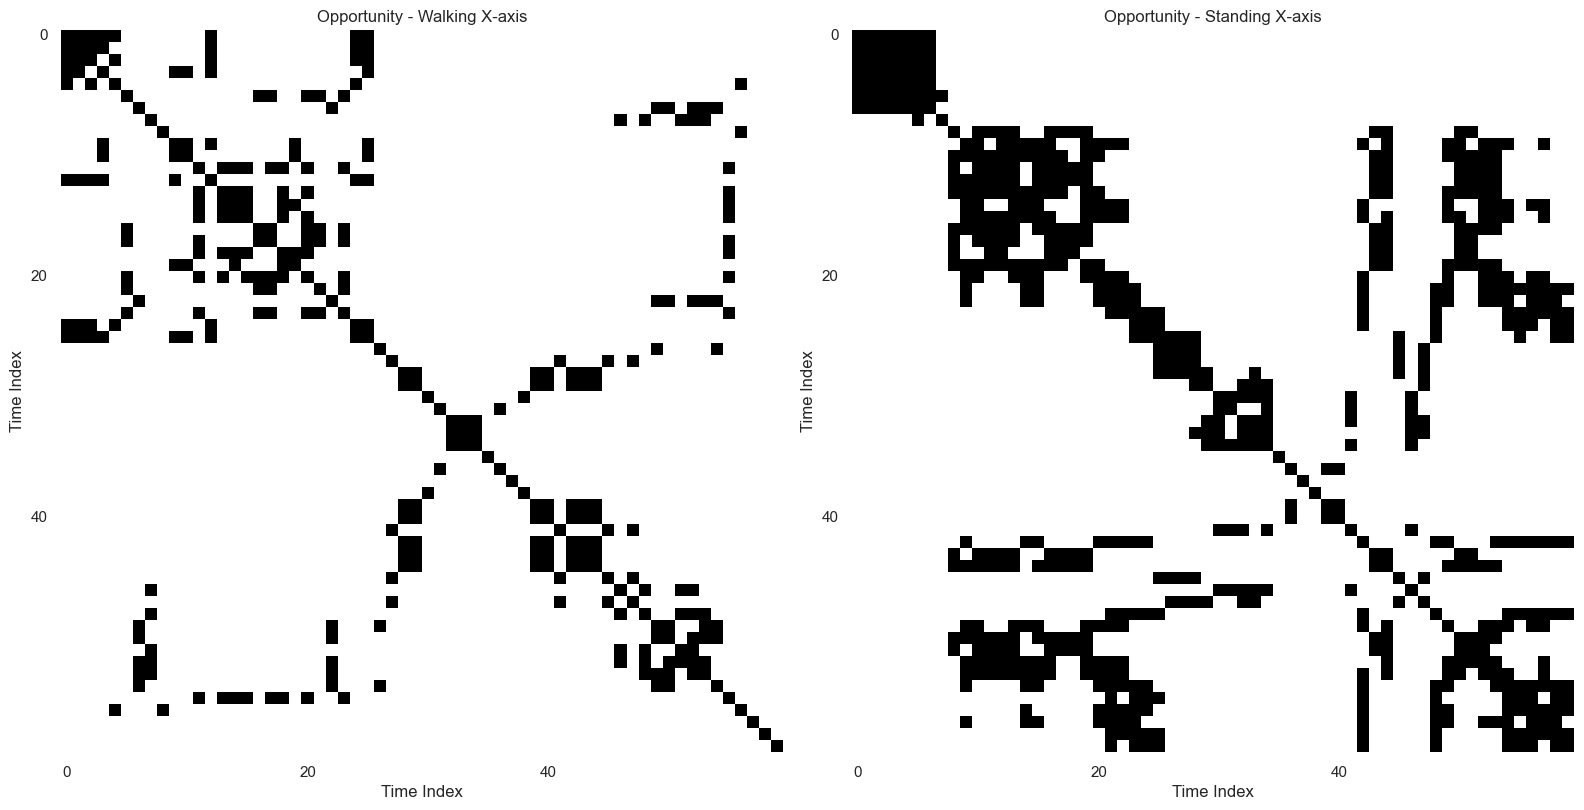

In [30]:
rec_matrix = plot_two_recurrence_matrices(walking_data['gyroX'].iloc[start:end].values, 
                                          standing_data['gyroX'].iloc[start:end].values, 
                                          "Opportunity - Walking X-axis", 
                                          "Opportunity - Standing X-axis", 
                                          threshold_axis)

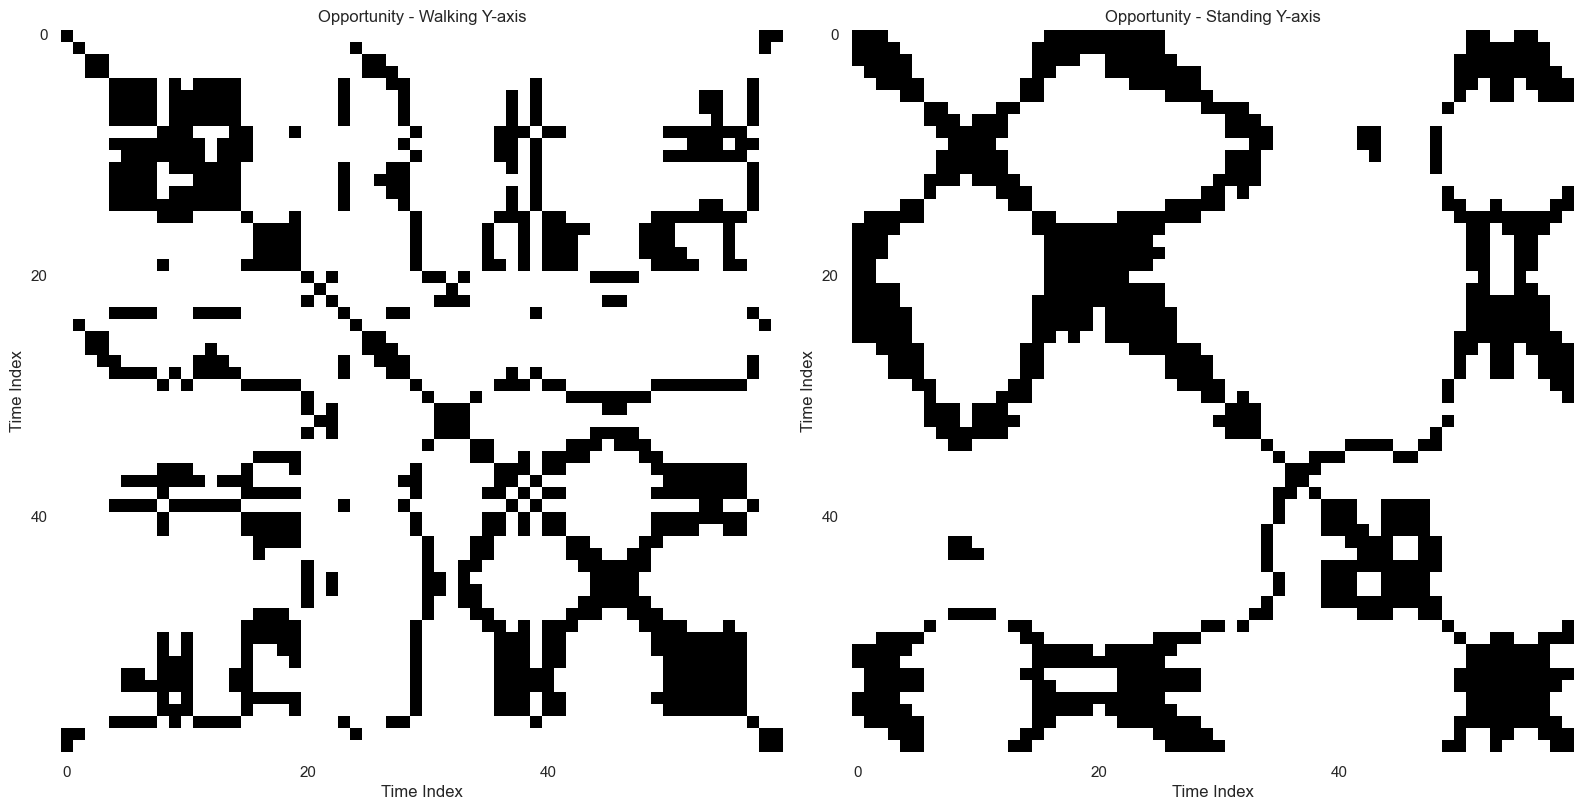

In [31]:
rec_matrix = plot_two_recurrence_matrices(walking_data['gyroY'].iloc[start:end].values, 
                                          standing_data['gyroY'].iloc[start:end].values, 
                                          "Opportunity - Walking Y-axis", 
                                          "Opportunity - Standing Y-axis", 
                                          threshold_axis)

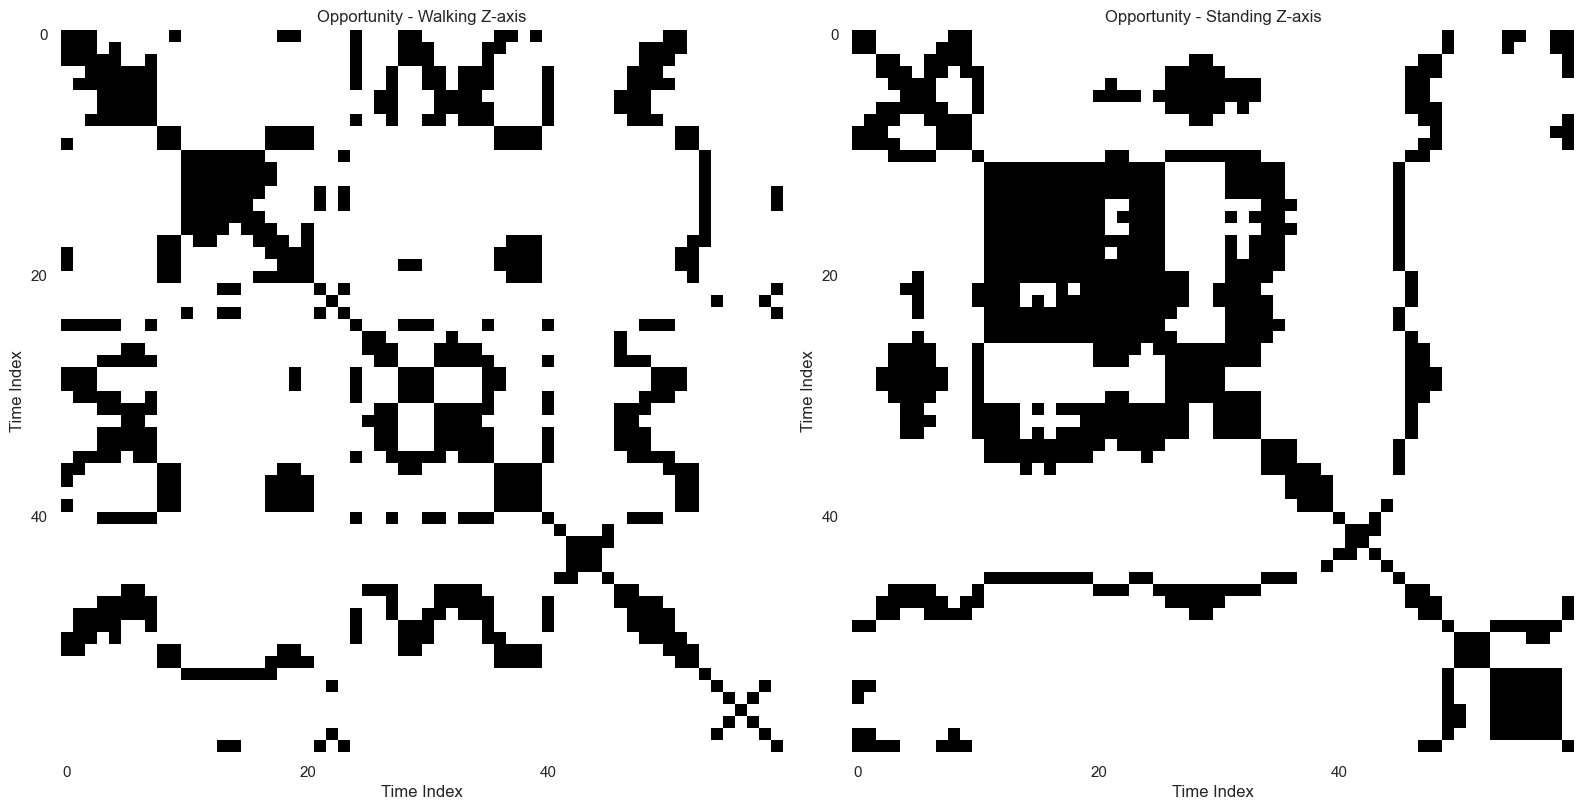

In [32]:
rec_matrix = plot_two_recurrence_matrices(walking_data['gyroZ'].iloc[start:end].values, 
                                          standing_data['gyroZ'].iloc[start:end].values, 
                                          "Opportunity - Walking Z-axis", 
                                          "Opportunity - Standing Z-axis", 
                                          threshold_axis)

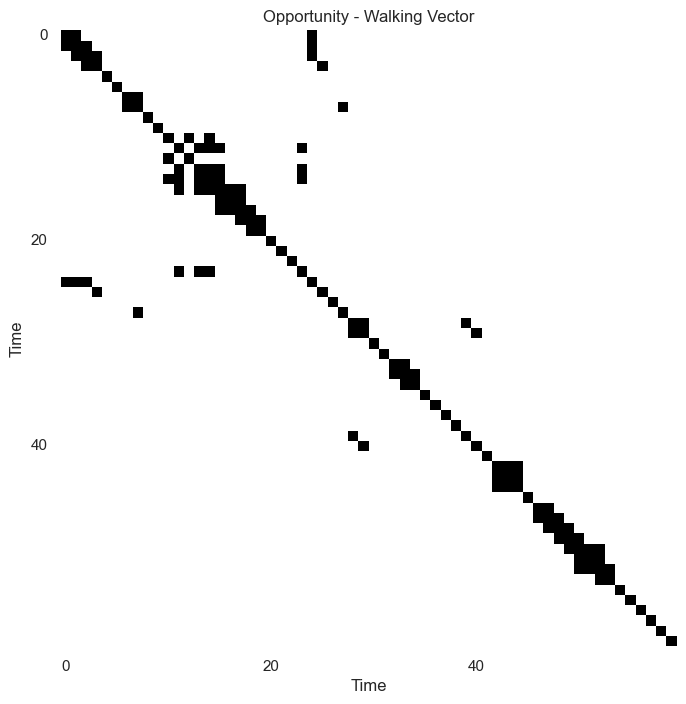

In [33]:
R = recurrence_plot_vector(walking_vectors[start:end,:], threshold_vector)
plot_recurrence_matrix_vector(R, 'Opportunity - Walking Vector')

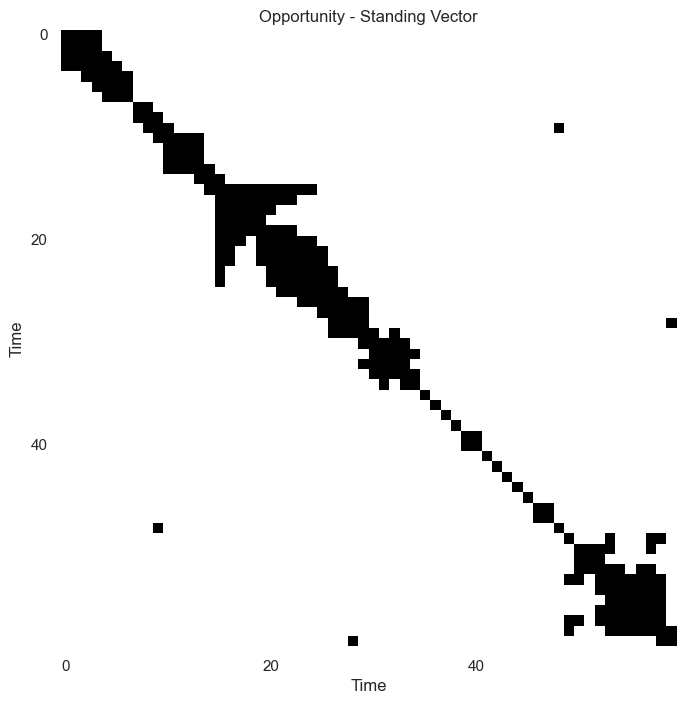

In [34]:
R = recurrence_plot_vector(standing_vectors[start:end,:], threshold_vector)
plot_recurrence_matrix_vector(R, 'Opportunity - Standing Vector')

### Multiple Recurrence Plots

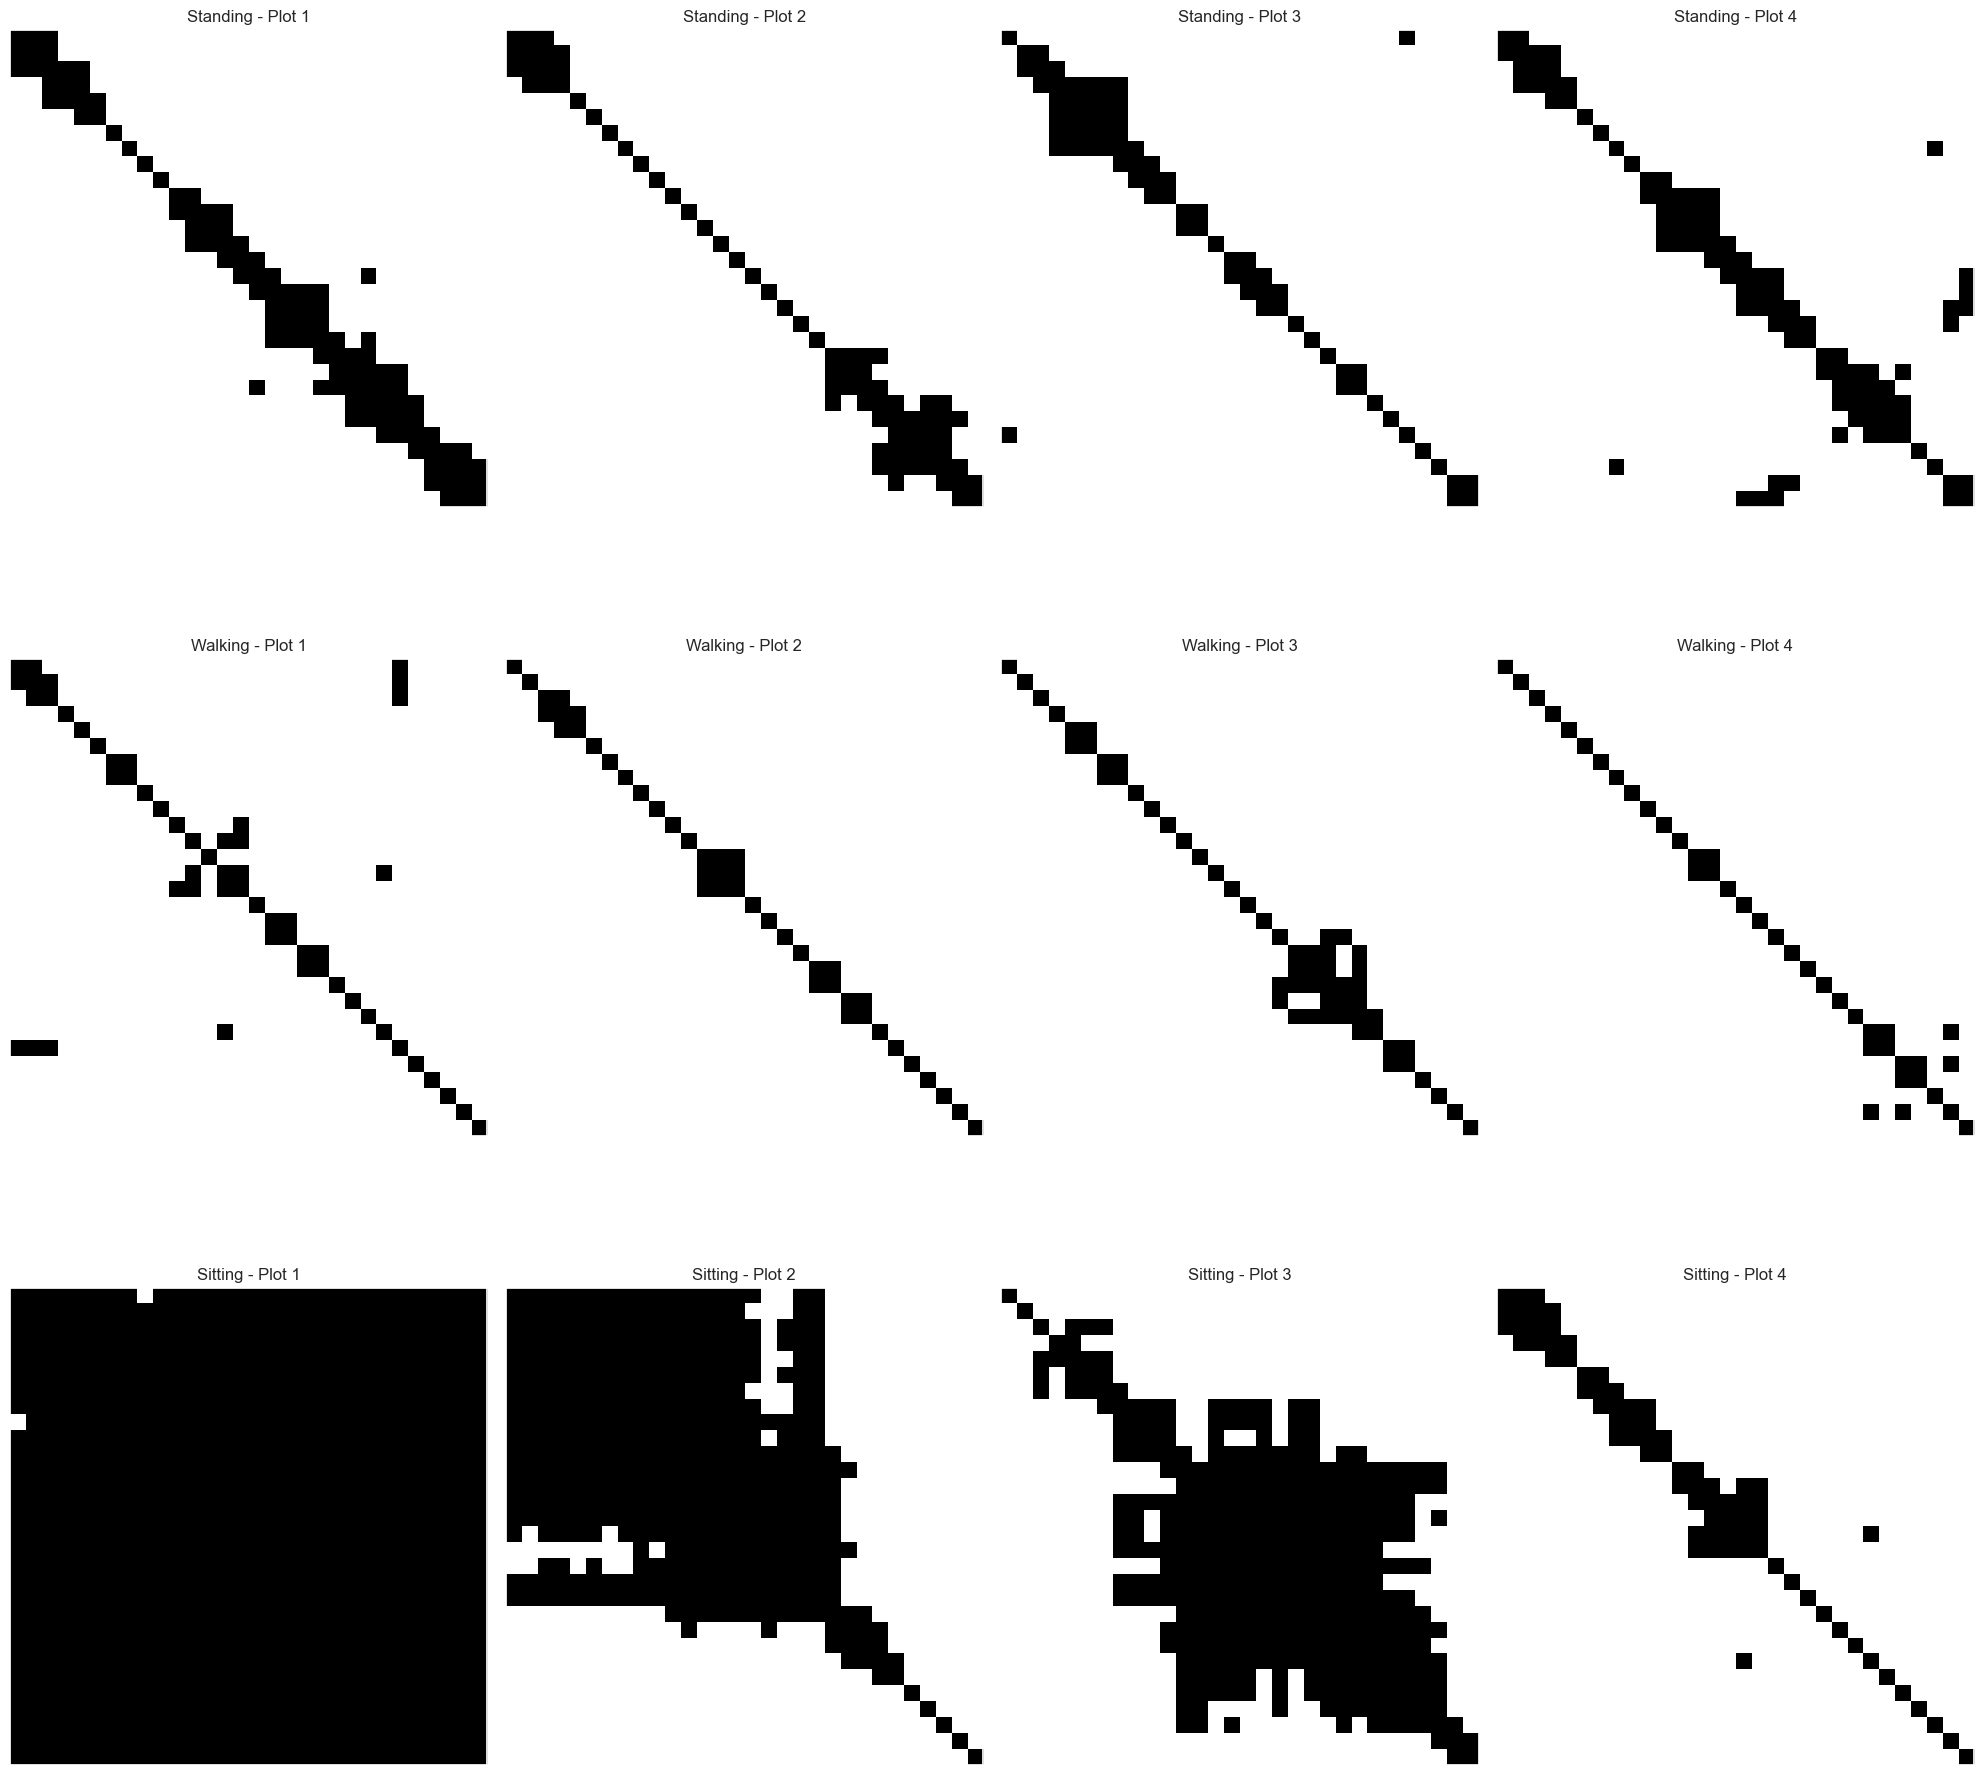

In [38]:
data = {"Standing": standing_vectors, "Walking": walking_vectors, "Sitting": sitting_vectors}

plot_recurrence_by_activity(data, 0.15, step=30)